In [1]:
import gc
import itertools
import math
import time
from collections import Counter
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# We use the Mac GPU (Metal/MPS) if available.
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

print(f"Device: {DEVICE}")

Device: mps


In [2]:
%pip install -q gluonts


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.10/bin/python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
# We load the data here.

from gluonts.dataset.repository.datasets import get_dataset


def load_gluonts_dataset(name: str):
    """Load a GluonTS dataset and extract as numpy arrays.
    
    Downloads once, then cached in ~/.gluonts.
    
    """
    try:
        ds = get_dataset(name, regenerate=False)
        series = [
            np.array(entry["target"], dtype=np.float32) for entry in ds.train
        ]
        total_points = sum(len(s) for s in series)
        print(f"  Dataset loaded: {name}: {len(series)} series, {total_points:,} points")
        return series
    except Exception as e:
        print(f"  {name}: Failed to load gluonts dataset :( - {e}")
        return []


datasets_to_load = [
    "electricity_hourly",   # 321 series - energy consumption
    "traffic",              # 862 series - road occupancy
    "m4_daily",             # 4,227 series - M4 competition
    "m4_weekly",            # 359 series - M4 competition
    "tourism_monthly",      # 366 series - tourism arrivals
]

# Datasets differ hugely in how many series they contribute.
# SeriesWindows gives every dataset an equal share of the sampling probability regardless of size.

all_series, all_names = [], []
for ds_name in datasets_to_load:
    # We load only the first 2000 series of each dataset.
    series = load_gluonts_dataset(ds_name)[:2000]
    all_series.extend(series)
    all_names.extend([ds_name] * len(series))
    gc.collect()

print(
    f"TOTAL: {len(all_series):,} series, {sum(len(s) for s in all_series):,} data points"
)

/Users/alekseivanov/Library/Python/3.10/lib/python/site-packages/gluonts/json.py:102: UserWarning: Using `json`-module for json-handling. Consider installing one of `orjson`, `ujson` to speed up serialization and deserialization.
  warnings.warn(


  Dataset loaded: electricity_hourly: 321 series, 8,428,176 points
  Dataset loaded: traffic: 862 series, 12,099,032 points
  Dataset loaded: m4_daily: 4227 series, 9,964,658 points
  Dataset loaded: m4_weekly: 359 series, 366,912 points
  Dataset loaded: tourism_monthly: 366 series, 100,496 points
TOTAL: 3,908 series, 25,571,697 data points


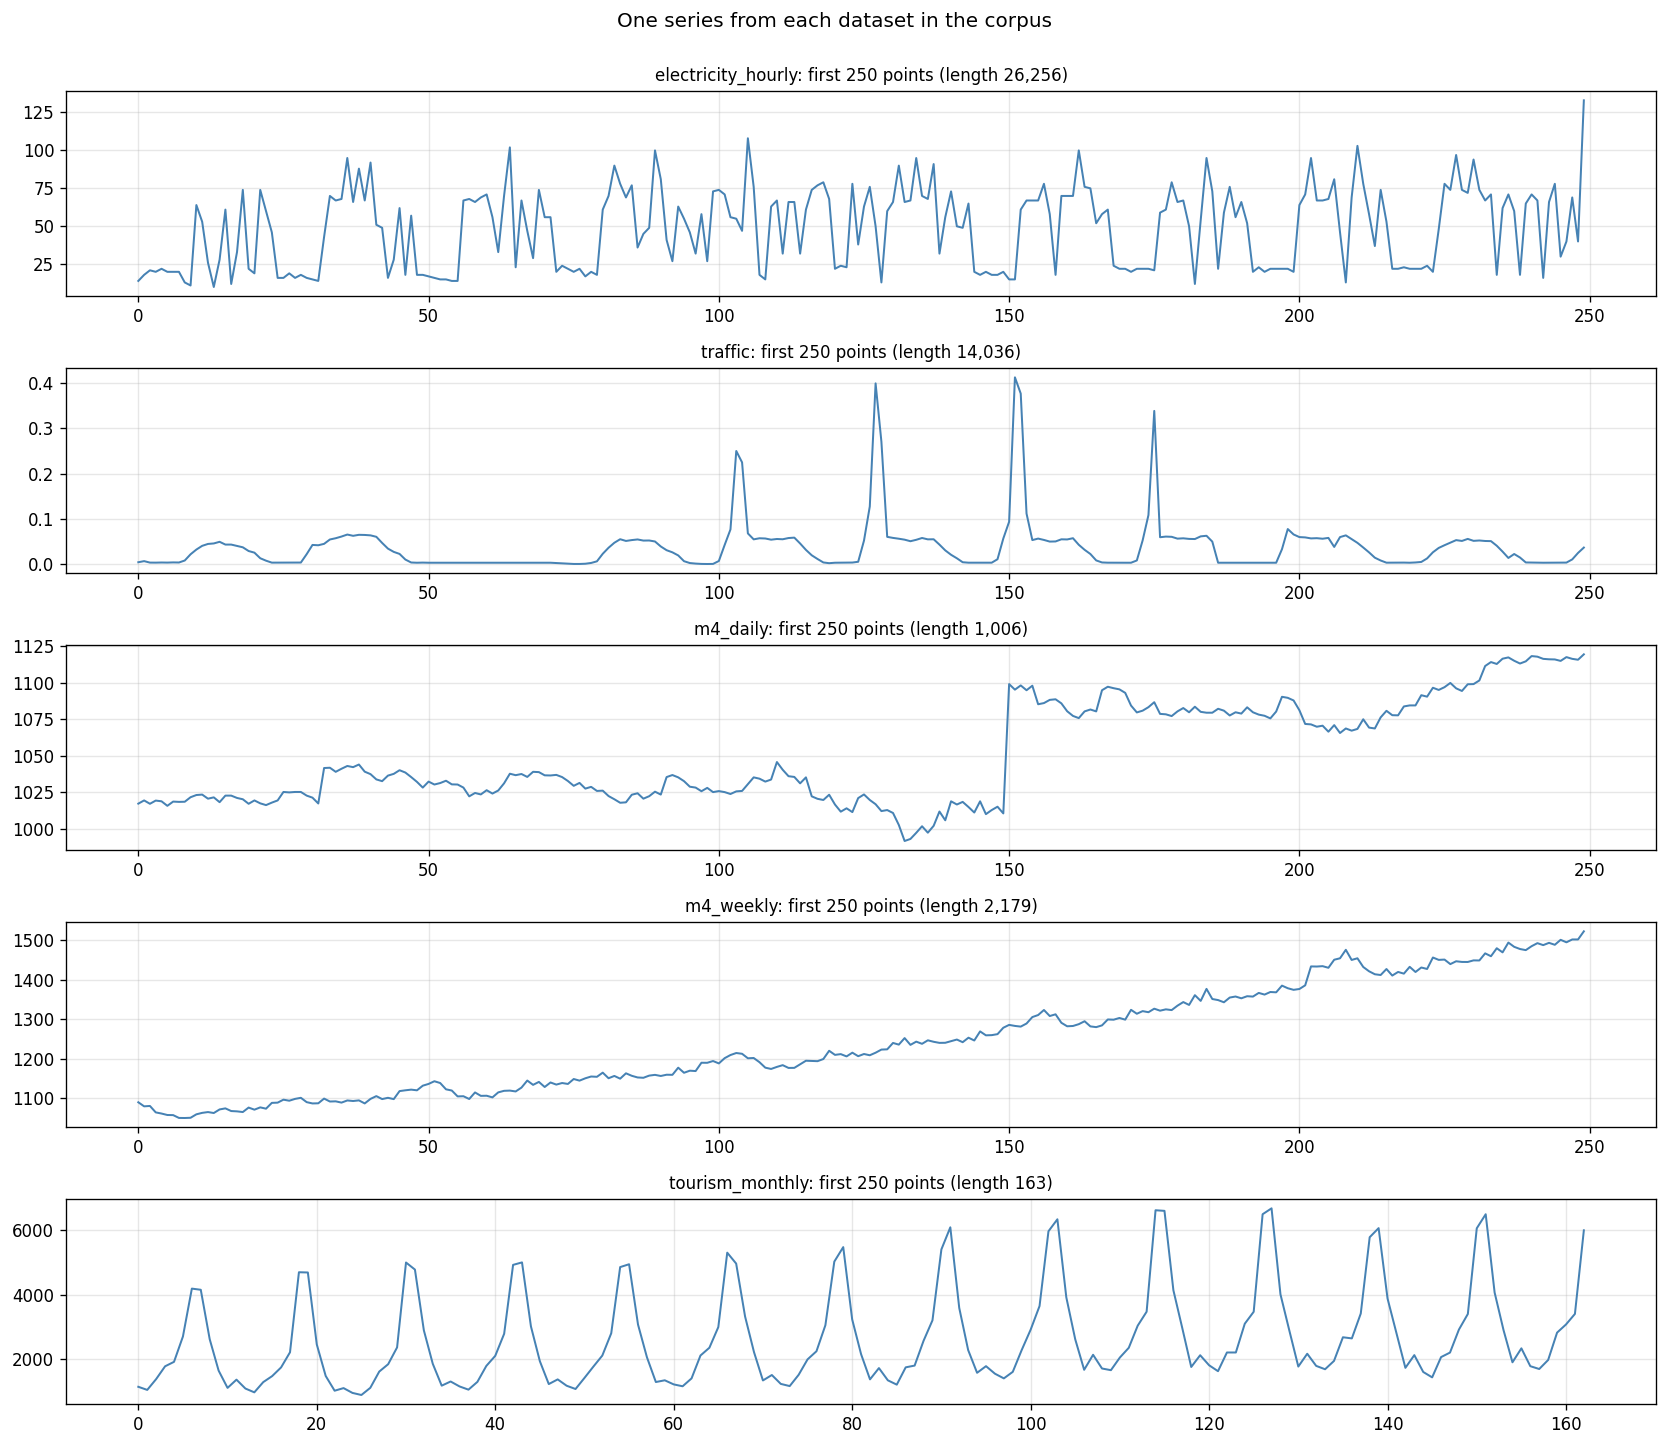

In [4]:
# Visualize one sample series per dataset
fig, axes = plt.subplots(len(datasets_to_load), 1, figsize=(14, 12))
for ax, ds_name in zip(axes, datasets_to_load):
    s = all_series[all_names.index(ds_name)]
    ax.plot(s[:250], linewidth=1.2, color="steelblue")
    ax.set_title(f"{ds_name}: first 250 points (length {len(s):,})", fontsize=10)
plt.suptitle("One series from each dataset in the corpus", fontsize=12, y=1.0)
plt.tight_layout()
plt.show()

In [5]:
CONTEXT_LEN = 128   # context steps (history)
HORIZON = 32        # forecast steps (future)
PATCH_LEN = 16      # 1 patch = 16 consecutive values
N_CTX_PATCHES = CONTEXT_LEN // PATCH_LEN    # 8 patches of 16 (8 * 16 = 128)
N_TGT_PATCHES = HORIZON // PATCH_LEN        # 2 patches of 16 (2 * 16 = 32)
PRETRAIN_WINDOW_PATCHES = 12                # pretraining sees 12-patch windows

# The context length and horizon must be multiples of the patch length.
assert CONTEXT_LEN % PATCH_LEN == 0 and HORIZON % PATCH_LEN == 0

# We require a minimum length for series to be eligible for training.
MIN_LEN = CONTEXT_LEN + 2 * HORIZON

# Filter our series to those that are long enough.
keep = [i for i, s in enumerate(all_series) if len(s) >= MIN_LEN]
print(f"{len(keep):,} of {len(all_series):,} series are long enough (>= {MIN_LEN} points)")

split_rng = np.random.default_rng(0)          # fixed, so the held-out set is the same on every run
perm = split_rng.permutation(keep)
n_heldout = max(1, int(len(perm) * 0.1))
heldout_idx, train_idx = perm[:n_heldout], perm[n_heldout:]

train_series = [all_series[i] for i in train_idx]
train_names = [all_names[i] for i in train_idx]
# Held-out series lose their last HORIZON steps: that tail is the test future, never seen by anything.
heldout_series = [all_series[i] for i in heldout_idx]
heldout_names = [all_names[i] for i in heldout_idx]
heldout_history = [s[:-HORIZON] for s in heldout_series]


print("\nCorpus split: training vs held-out series")
for ds_name in datasets_to_load:
    n_tr = train_names.count(ds_name) 
    n_ho = heldout_names.count(ds_name)
    pts = sum(len(s) for s, n in zip(train_series, train_names) if n == ds_name)
    print(f"  {ds_name:>18}: {n_tr:5d} training series ({pts:>12,} points)   {n_ho:4d} held-out series")
train_points = sum(len(s) for s in train_series)
print(f"  {'total':>18}: {len(train_series):5d} training series ({train_points:>12,} points, {train_points // PATCH_LEN:,} patches)   "
      f"{len(heldout_series):4d} held-out series")

3,647 of 3,908 series are long enough (>= 192 points)

Corpus split: training vs held-out series
  electricity_hourly:   282 training series (   7,404,192 points)     39 held-out series
             traffic:   786 training series (  11,032,296 points)     76 held-out series
            m4_daily:  1682 training series (   4,071,941 points)    196 held-out series
           m4_weekly:   271 training series (     339,962 points)     23 held-out series
     tourism_monthly:   262 training series (      78,438 points)     30 held-out series
               total:  3283 training series (  22,926,829 points, 1,432,926 patches)    364 held-out series


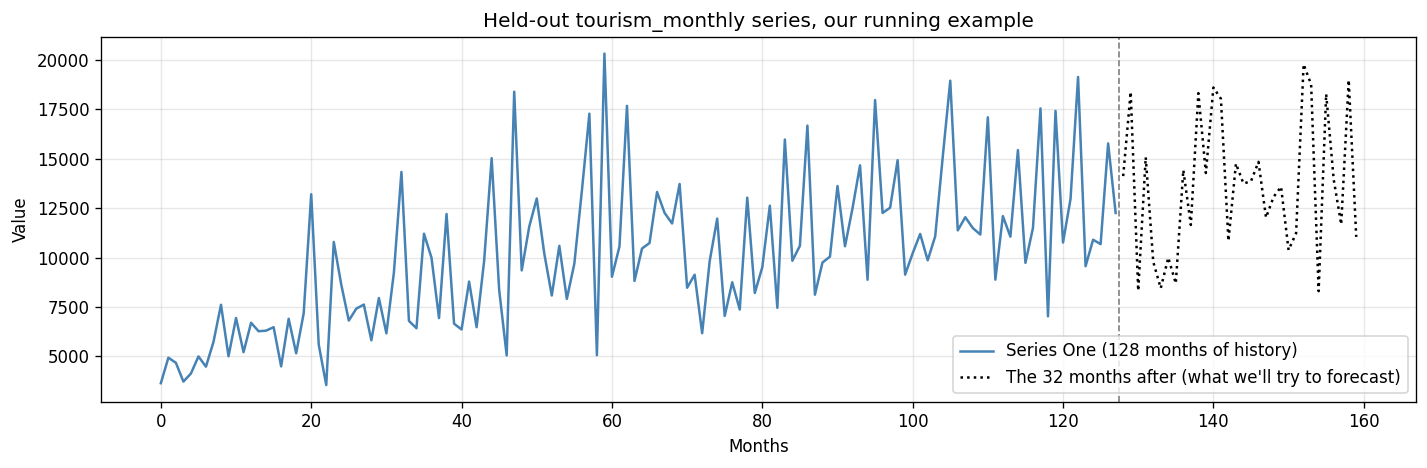

context_length = 128 (8 patches of 16)
horizon = 32 (2 patches of 16)


In [6]:
# The first held-out tourism series. Its last 128 known months, and the 32 that follow.
SERIES_ONE = next(i for i, n in enumerate(heldout_names) if n == "tourism_monthly")
series_one_context = heldout_history[SERIES_ONE][-CONTEXT_LEN:]
series_one_future = heldout_series[SERIES_ONE][-HORIZON:]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(range(CONTEXT_LEN), series_one_context, color="steelblue", label="Series One (128 months of history)")
ax.plot(range(CONTEXT_LEN, CONTEXT_LEN + HORIZON), series_one_future, color="black",
        linestyle=":", label="The 32 months after (what we'll try to forecast)")
ax.axvline(CONTEXT_LEN - 0.5, color="gray", linestyle="--", linewidth=1)
ax.set_title("Held-out tourism_monthly series, our running example")
ax.set_xlabel("Months"); ax.set_ylabel("Value")
ax.legend()
plt.tight_layout()
plt.show()

print(f"context_length = {CONTEXT_LEN} ({N_CTX_PATCHES} patches of {PATCH_LEN})")
print(f"horizon = {HORIZON} ({N_TGT_PATCHES} patches of {PATCH_LEN})")

In [7]:
def windows_of(x, context_len=CONTEXT_LEN, horizon=HORIZON, stride=1):
    """Slices a single raw series into overlapping (context, future) windows."""
    starts = range(0, len(x) - context_len - horizon + 1, stride)
    ctx = np.stack([x[s : s + context_len] for s in starts])
    fut = np.stack(
        [x[s + context_len : s + context_len + horizon] for s in starts]
    )
    return ctx.astype(np.float32), fut.astype(np.float32)


class SeriesWindows:
    """Wraps a list of series with fixed context/horizon windowing.

    `.sample(n)` draws n random windows: a random series first, then a
    random position inside it. Every dataset is weighted equally
    regardless of how many series it has.
    """

    def __init__(
        self, series_list, names=None, context_len=CONTEXT_LEN, horizon=HORIZON
    ):
        """Builds the pool and computes per-series sampling weights."""
        self.series = list(series_list)
        self.context_len, self.horizon = context_len, horizon
        names = list(names) if names is not None else [None] * len(self.series)
        # Per-series weight = 1 / (# series from that dataset in this pool).
        # Every dataset contributes an equal share of sampling probability
        # regardless of how many series it has (e.g. m4_daily's ~1.8k
        # training series vs. electricity_hourly's ~290).
        counts = Counter(names)
        w = np.array([1.0 / counts[n] for n in names], dtype=np.float64)
        self.probs = w / w.sum()
        self.lengths = np.array([len(s) for s in self.series])

    def _draw(self, n, length, generator):
        """Draws n random raw windows of a given length from the pool."""
        p = self.probs * (self.lengths >= length)
        idx = generator.choice(len(self.series), size=n, p=p / p.sum())
        out = []
        for i in idx:
            s = self.series[i]
            st = generator.integers(0, len(s) - length + 1)
            out.append(s[st : st + length])
        return np.stack(out).astype(np.float32)

    def sample(self, n, generator=None):
        """Draws n random (context, future) window pairs.

        Flat contexts (dead sensors) are dropped after sampling.

        Example:
            With context_len=128 and horizon=32, pool.sample(256)
            draws 256 raw 160-step windows, splits each into its
            first 128 steps (ctx) and last 32 steps (fut).
        """
        w = self._draw(n, self.context_len + self.horizon, generator or rng)
        ctx, fut = w[:, : self.context_len], w[:, self.context_len :]
        return ctx, fut

    def sample_window(self, n, n_patches, patch_len=PATCH_LEN, generator=None):
        """Draws n random raw windows of `n_patches` consecutive patches."""
        return self._draw(n, n_patches * patch_len, generator or rng)


def normalize(context, future=None, eps=1e-6):
    """Applies context-only z-score normalization (ReVIN-style).

    Sigma is floored at 0.1% of the window's mean level. Without the
    floor, a nearly flat context (a sensor idling for a week) turns the
    next jump into a target of thousands of standard deviations, and one
    such window can wreck a whole fit.

    Example:
        normalize(np.array([[1.0, 2.0, 3.0]])) computes mu = 2.0 and
        sigma ~= 0.816, then returns context_n ~= [[-1.22, 0.0, 1.22]]
        alongside mu and sigma -- the context rescaled to zero mean
        and unit variance. Passing a future array normalizes it with
        that same mu/sigma (never its own), which is what keeps the
        model from peeking at the future's scale.
    """
    mu = context.mean(axis=-1, keepdims=True)
    sigma = (
        np.maximum(
            context.std(axis=-1, keepdims=True),
            # A flat eps would still let a near-zero std blow up the next real jump
            # into thousands of sigmas.
            # Tying the floor to 0.1% of this window's own mean keeps it appropriate
            # whether the series lives in the tens or the tens of thousands.
            1e-3 * np.abs(context).mean(axis=-1, keepdims=True),
        )
        + eps
    )
    context_n = (context - mu) / sigma
    if future is None:
        return context_n, mu, sigma
    return context_n, (future - mu) / sigma, mu, sigma


def denormalize(x_n, mu, sigma):
    """Reverses `normalize`, mapping normalized values back to raw scale.

    Example:
        Given mu = 2.0 and sigma = 0.816 from the normalize example
        above, denormalize(np.array([[-1.22, 0.0, 1.22]]), mu, sigma)
        returns ~= [[1.0, 2.0, 3.0]] -- the original raw values,
        undoing the z-score. A model's normalized-space predictions
        are passed through this before being compared against real
        forecasts.
    """
    return x_n * sigma + mu

  context [0 1 2 3] -> future [4 5]
  context [1 2 3 4] -> future [5 6]
  context [2 3 4 5] -> future [6 7]
  context [3 4 5 6] -> future [7 8]
  context [4 5 6 7] -> future [8 9]
pool.sample(4): ctx (4, 128), fut (4, 32)
Sampling probability: {'m4_daily': 0.2, 'traffic': 0.2, 'electricity_hourly': 0.2, 'tourism_monthly': 0.2, 'm4_weekly': 0.2}

Series One: mu = 10081.6, sigma = 3793.7
  normalized context: mean 0.00, std 1.00
  normalized future:  mean 0.94, std 0.92


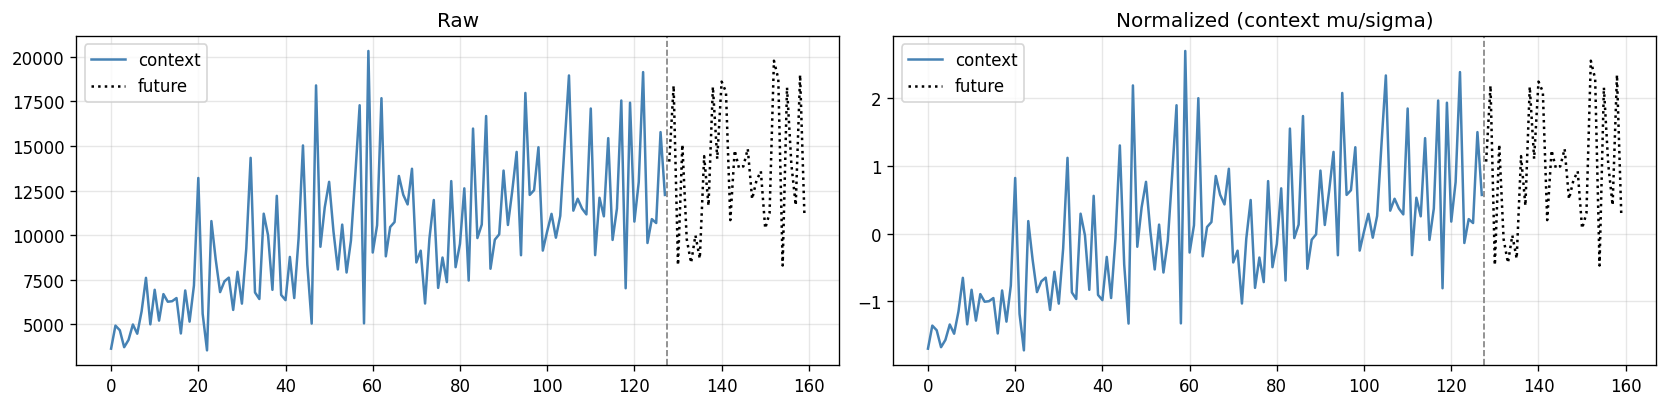

In [8]:
# Quick test of the previous cell.
sample_series = np.arange(10, dtype=np.float32)
toy_ctx, toy_fut = windows_of(sample_series, context_len=4, horizon=2)
for c, f in zip(toy_ctx, toy_fut):
    print(f"  context {c.astype(int)} -> future {f.astype(int)}")

# Random windows from the whole training pool, every dataset weighted equally.
pool = SeriesWindows(train_series, train_names)
ctx, fut = pool.sample(4, generator=np.random.default_rng(0))
print(f"pool.sample(4): ctx {ctx.shape}, fut {fut.shape}")

probs_per_ds = Counter()
for p, n in zip(pool.probs, train_names):
    probs_per_ds[n] += p
print("Sampling probability:", {k: round(float(v), 3) for k, v in probs_per_ds.items()})

# Normalize / denormalize on series one.
ctx_n, fut_n, mu, sigma = normalize(series_one_context[None], series_one_future[None])
print(f"\nSeries One: mu = {mu.item():.1f}, sigma = {sigma.item():.1f}")
print(f"  normalized context: mean {ctx_n.mean():.2f}, std {ctx_n.std():.2f}")
print(f"  normalized future:  mean {fut_n.mean():.2f}, std {fut_n.std():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, (c, f, title) in zip(axes, [(series_one_context, series_one_future, "Raw"),
                                     (ctx_n[0], fut_n[0], "Normalized (context mu/sigma)")]):
    ax.plot(range(CONTEXT_LEN), c, color="steelblue", label="context")
    ax.plot(range(CONTEXT_LEN, CONTEXT_LEN + HORIZON), f, color="black", linestyle=":", label="future")
    ax.axvline(CONTEXT_LEN - 0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

In [9]:
# Evaluation windows, fixed once. Test = the last 128 -> 32 of every held-out series (the 32 nothing trains on).

# Test is [L - C - H : L - H] with future [L - H : L]
test_ctx = np.stack(
    [s[-(CONTEXT_LEN + HORIZON) : -HORIZON] for s in heldout_series]
).astype(np.float32)
test_fut = np.stack([s[-HORIZON:] for s in heldout_series]).astype(np.float32)
test_names = np.array(heldout_names)

# heldout_history is the same as heldout_series but with the last HORIZON steps removed. 
# We use it to create validation windows that are disjoint from the test windows.
# Validation is [L - C - 2H : L - 2H] with future [L - 2H : L]
val_ctx = np.stack(
    [s[-(CONTEXT_LEN + HORIZON) : -HORIZON] for s in heldout_history]
).astype(np.float32)
val_fut = np.stack([s[-HORIZON:] for s in heldout_history]).astype(np.float32)


def compute_metrics(pred, actual):
    """Computes MAE, RMSE, and MAPE for a single window."""
    pred, actual = np.asarray(pred, dtype=np.float64), np.asarray(
        actual, dtype=np.float64
    )
    mae = np.mean(np.abs(pred - actual))
    rmse = np.sqrt(np.mean((pred - actual) ** 2))
    mape = np.mean(np.abs((pred - actual) / (np.abs(actual) + 1e-8))) * 100
    return {"MAE": float(mae), "RMSE": float(rmse), "MAPE": float(mape)}


def naive_forecast(ctx):
    """Repeats the last known value across the forecast horizon.

    This is the universal reference forecast across frequencies.

    Example:
        With HORIZON = 32, naive_forecast(np.array([[1.0, 2.0, 3.0]]))
        returns an array of shape (1, 32) where every entry is 3.0 --
        "tomorrow looks like today," the baseline that scaled_mae
        divides by.
    """
    return np.repeat(ctx[:, -1:], HORIZON, axis=1)


def scaled_mae(pred, ctx, fut):
    """Computes MAE scaled by the naive forecast's MAE on the same windows."""
    err = np.abs(pred - fut).mean(axis=1)
    naive_err = np.abs(naive_forecast(ctx) - fut).mean(axis=1) + 1e-6
    return float(np.mean(err / naive_err))


def seam(pred, ctx):
    """Measures the discontinuity between the context and the forecast.

    Computes the median of |first forecast value - last observed value|
    divided by the context's standard deviation. The ground truth's own
    seam is the number to aim at: a forecast that starts far from where
    the data stopped is drifting toward the middle of its context window
    instead of continuing the series.
    """
    # Basically, this checks whether a forecast starts where the series
    # actually left off, or whether it visibly jumps at the boundary.
    return float(
        np.median(np.abs(pred[:, 0] - ctx[:, -1]) / (ctx.std(axis=1) + 1e-9))
    )


def test_table(pred):
    """Computes scaled MAE on the test windows, per dataset and overall."""
    # Because this corpus has multiple datasets, we report scaled MAE per dataset and overall.
    row = {
        n: scaled_mae(
            pred[test_names == n], test_ctx[test_names == n], test_fut[test_names == n]
        )
        for n in datasets_to_load
    }
    row["all"] = scaled_mae(pred, test_ctx, test_fut)
    return row


def val_scaled_mae(pred):
    """Computes scaled MAE on the validation windows."""
    return scaled_mae(pred, val_ctx, val_fut)


train_pool = SeriesWindows(train_series, train_names)

# Result: 364 test windows (one per held-out series), 364 validation windows
# We have 3,647 series and because we hold out 10% of them, we have 364 held-out series.
# Each held-out series contributes one test window and one validation window.
print(f"{len(test_ctx)} test windows (one per held-out series), {len(val_ctx)} validation windows")

364 test windows (one per held-out series), 364 validation windows


In [10]:
# compute_metrics on a toy forecast that is off by +1 everywhere.
print("compute_metrics([2,3,4] vs [1,2,3]):", compute_metrics([2, 3, 4], [1, 2, 3]))

print("shape test_ctx = ", test_ctx.shape)
print("test_ctx[0][:10] = ", test_ctx[0][:10])

naive_frcst = naive_forecast(test_ctx)
print("naive_forecast = ", naive_frcst[0][:10])

naive_table = test_table(naive_frcst)
perfect_table = test_table(test_fut)
print("perfe_forecast = ", test_fut[0][:10])

# The naive forecast scores 1.0, a perfect forecast 0.0.
print("naive forecast:  ", {k: round(v, 3) for k, v in naive_table.items()})
print("perfect forecast:", {k: round(v, 3) for k, v in perfect_table.items()})

# Naive starts exactly at the last observed value. the truth's own seam is the target.
print(f"seam -- naive: {seam(naive_frcst, test_ctx):.3f}, ground truth: {seam(test_fut, test_ctx):.3f}")

compute_metrics([2,3,4] vs [1,2,3]): {'MAE': 1.0, 'RMSE': 1.0, 'MAPE': 61.11111065740742}
shape test_ctx =  (364, 128)
test_ctx[0][:10] =  [0.0478 0.0472 0.0443 0.0553 0.0541 0.0541 0.0542 0.0634 0.0486 0.0592]
naive_forecast =  [0.0542 0.0542 0.0542 0.0542 0.0542 0.0542 0.0542 0.0542 0.0542 0.0542]
perfe_forecast =  [0.0559 0.0613 0.0666 0.0567 0.0635 0.0517 0.0517 0.0598 0.0382 0.0266]
naive forecast:   {'electricity_hourly': 1.0, 'traffic': 1.0, 'm4_daily': 1.0, 'm4_weekly': 1.0, 'tourism_monthly': 1.0, 'all': 1.0}
perfect forecast: {'electricity_hourly': 0.0, 'traffic': 0.0, 'm4_daily': 0.0, 'm4_weekly': 0.0, 'tourism_monthly': 0.0, 'all': 0.0}
seam -- naive: 0.000, ground truth: 0.130


In [11]:
class TrainingLoop:
    def __init__(self, step_fn, val_fn=None, model=None, desc=""):
        self.step_fn, self.val_fn, self.model, self.desc = step_fn, val_fn, model, desc
        self.losses = []
        self.val_history = []   # list of (step, val_metric)
        self.best_val, self.best_state, self.best_step = float("inf"), None, None

    def run(self, n_steps, log_every=200, val_every=None, verbose=True):
        val_every = val_every or log_every
        for step in range(1, n_steps + 1):
            self.losses.append(self.step_fn())
            log_now = step % log_every == 0 or step == n_steps
            val_now = self.val_fn is not None and (step % val_every == 0 or step == n_steps)
            if val_now:
                v = self.val_fn()
                self.val_history.append((step, v))
                if self.model is not None and v < self.best_val:
                    self.best_val, self.best_step = v, step
                    self.best_state = {k: t.detach().clone() for k, t in self.model.state_dict().items()}
            if log_now and verbose:
                msg = f"  [{self.desc}] step {step:5d}/{n_steps}  loss {np.mean(self.losses[-log_every:]):.5f}"
                if val_now:
                    msg += f"  val {v:.4f}"
                print(msg)
        if self.best_state is not None:
            self.model.load_state_dict(self.best_state)
            if verbose:
                print(f"  [{self.desc}] restored best checkpoint: step {self.best_step}, val {self.best_val:.4f}")
        return self.losses

In [12]:
# Quick training loop check.
toy_model = nn.Linear(1, 1)
toy_opt = optim.SGD(toy_model.parameters(), lr=0.1)
toy_x = torch.linspace(-1, 1, 64)[:, None]
toy_y = 3 * toy_x + 1

def toy_step():
    loss = F.mse_loss(toy_model(toy_x), toy_y)
    toy_opt.zero_grad(); loss.backward(); toy_opt.step()
    return loss.item()

# Scripted validation scores, so we know the best one is the 2nd check (step 10).
# We also record the weights at each check to confirm the right checkpoint gets restored.
scripted_val = iter([0.5, 0.2, 0.9, 0.4])
weights_at_check = []

# Fake validation function that returns made up scores from scripted_val. We call this 4 times.
def toy_val():
    weights_at_check.append(toy_model.weight.item())
    return next(scripted_val)

# We validate every 5th step, so 20 / 5 = 4 times validation funciton is called.
loop = TrainingLoop(toy_step, toy_val, model=toy_model, desc="toy")
losses = loop.run(n_steps=20, log_every=5)

print(f"loss: {losses[0]:.3f} -> {losses[-1]:.3f}")
print(f"validated at steps {[s for s, _ in loop.val_history]}, best step {loop.best_step}")
print(f"weight at step 10: {weights_at_check[1]:.4f}, weight after run: {toy_model.weight.item():.4f}")

  [toy] step     5/20  loss 1.33311  val 0.5000
  [toy] step    10/20  loss 0.64821  val 0.2000
  [toy] step    15/20  loss 0.31726  val 0.9000
  [toy] step    20/20  loss 0.15551  val 0.4000
  [toy] restored best checkpoint: step 10, val 0.2000
loss: 1.748 -> 0.115
validated at steps [5, 10, 15, 20], best step 10
weight at step 10: 1.9038, weight after run: 1.9038


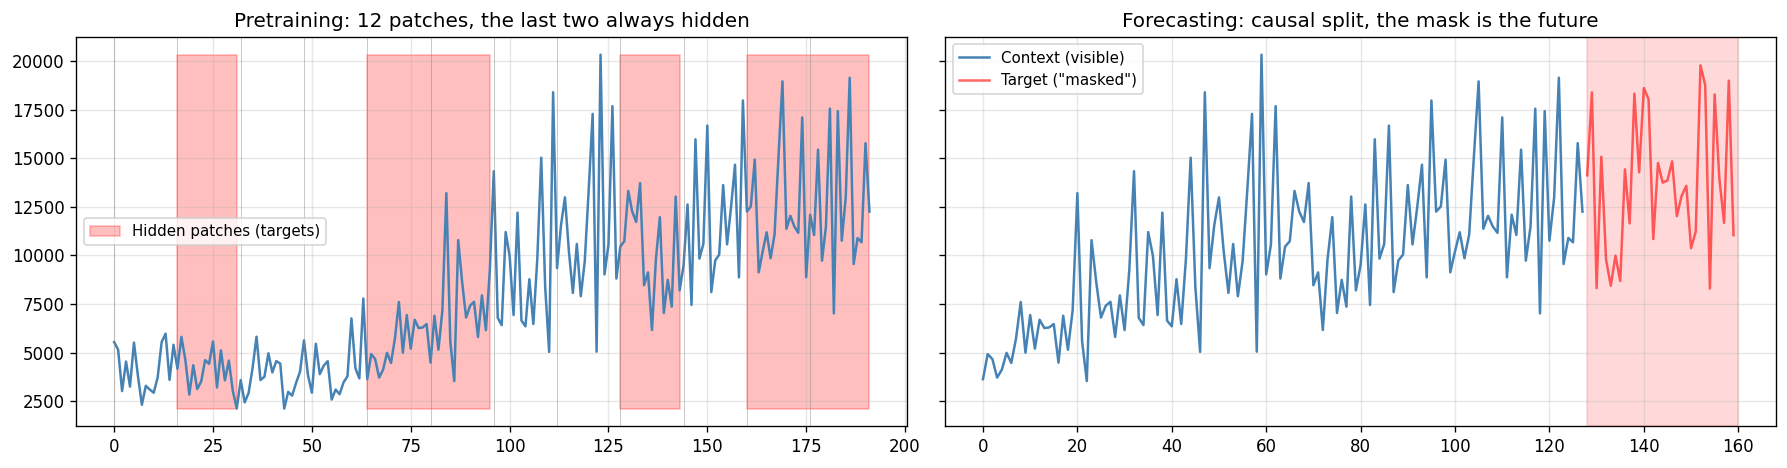

In [13]:
window12 = heldout_history[SERIES_ONE][-(PRETRAIN_WINDOW_PATCHES * PATCH_LEN):]

# Patch indicies to mask data.
hidden = np.array([1, 4, 5, 8, 10, 11])
mask12 = np.zeros(len(window12), dtype=bool)

# We hide the PATCH_LEN block.
for d in hidden:
    mask12[d * PATCH_LEN: (d + 1) * PATCH_LEN] = True

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
ax = axes[0]
ax.plot(window12, color="steelblue")
ax.fill_between(range(len(window12)), window12.min(), window12.max(), where=mask12, alpha=0.25, color="red", label="Hidden patches (targets)")

for d in range(PRETRAIN_WINDOW_PATCHES):
    ax.axvline(d * PATCH_LEN, color="gray", linewidth=0.5, alpha=0.5)
ax.set_title("Pretraining: 12 patches, the last two always hidden"); ax.legend(fontsize=9)

ax = axes[1]
ax.plot(range(CONTEXT_LEN), series_one_context, color="steelblue", label="Context (visible)")
ax.plot(range(CONTEXT_LEN, CONTEXT_LEN + HORIZON), series_one_future, color="red", alpha=0.6, label="Target (\"masked\")")
ax.axvspan(CONTEXT_LEN, CONTEXT_LEN + HORIZON, alpha=0.15, color="red")
ax.set_title("Forecasting: causal split, the mask is the future"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [14]:
def to_patches(x, patch_len=PATCH_LEN):
    """
    Convert (1, 128) to (1, 8, 16) // 8 patches of 16 values each.
    """
    n, L = x.shape
    assert L % patch_len == 0, f"{L} not divisible by patch_len={patch_len}"
    return x.reshape(n, L // patch_len, patch_len)

print("N_CTX_PATCHES = ", N_CTX_PATCHES)
print("N_CTX_PATCHES = ", N_CTX_PATCHES)
print("PATCH_LEN = ", PATCH_LEN)

# Position ids: 0..7 are the 8 context patches, 8 and 9 are the two target patches ("what comes next").
context_pos_ids = torch.arange(N_CTX_PATCHES).to(DEVICE)
target_pos_ids = torch.arange(N_CTX_PATCHES, N_CTX_PATCHES + N_TGT_PATCHES).to(DEVICE)
print(f"context_pos_ids: {context_pos_ids.tolist()}")
print(f"target_pos_ids:  {target_pos_ids.tolist()}")

batched = series_one_context[None, :]          # (128,) -> (1, 128): add a batch dimension
normalized, mu, sigma = normalize(batched)     # (1, 128), z-scored with the context's own mu/sigma
example_patches = to_patches(normalized)       # (1, 128) -> (1, 8, 16)

with np.printoptions(precision=2, suppress=True, linewidth=200):
    print(f"\nbatched         {batched.shape}:     last 10 = {batched[0, -10:]}")
    print(f"normalized      {normalized.shape}:     last 10 = {normalized[0, -10:]}   (mu = {mu.item():.1f}, sigma = {sigma.item():.1f})")
    print(f"example_patches {example_patches.shape}:  last 10 = {example_patches[0, -1, -10:]}   (the tail of patch 7)")

N_CTX_PATCHES =  8
N_CTX_PATCHES =  8
PATCH_LEN =  16
context_pos_ids: [0, 1, 2, 3, 4, 5, 6, 7]
target_pos_ids:  [8, 9]

batched         (1, 128):     last 10 = [ 7024. 17420. 10759. 12972. 19136.  9560. 10899. 10678. 15773. 12253.]
normalized      (1, 128):     last 10 = [-0.81  1.93  0.18  0.76  2.39 -0.14  0.22  0.16  1.5   0.57]   (mu = 10081.6, sigma = 3793.7)
example_patches (1, 8, 16):  last 10 = [-0.81  1.93  0.18  0.76  2.39 -0.14  0.22  0.16  1.5   0.57]   (the tail of patch 7)


In [15]:
EMBED_DIM = 128 
N_HEADS = 4
N_LAYERS = 3
FF_DIM = 256
PRED_DIM = 128      # Imagination width (its own width, with a projection in and out, as in TS-JEPA)
PRED_LAYERS = 2
MAX_POSITIONS = PRETRAIN_WINDOW_PATCHES   # 12 -- every position a patch can occupy


def sincos_positions(n_positions, dim):
    """Fixed sinusoidal position table (n_positions, dim) as in I-JEPA and TS-JEPA."""
    pos = np.arange(n_positions, dtype=np.float64)[:, None]
    i = np.arange(dim // 2, dtype=np.float64)[None, :]
    angles = pos / (10000 ** (2 * i / dim))
    return torch.tensor(np.concatenate([np.sin(angles), np.cos(angles)], axis=1), dtype=torch.float32)


def transformer_blocks(dim, n_heads, n_layers, ff_dim):
    layer = nn.TransformerEncoderLayer(d_model=dim, nhead=n_heads, dim_feedforward=ff_dim, dropout=0.0,
                                       batch_first=True, activation="gelu")
    return nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)


class Encoder(nn.Module):
    """Compresses a sequence of patches into position-aware embeddings."""

    def __init__(self, patch_len=PATCH_LEN, embed_dim=EMBED_DIM, n_heads=N_HEADS, n_layers=N_LAYERS,
                 ff_dim=FF_DIM, max_positions=MAX_POSITIONS):
        super().__init__()
        self.patch_embed = nn.Linear(patch_len, embed_dim)
        self.register_buffer("pos_table", sincos_positions(max_positions, embed_dim))
        self.transformer = transformer_blocks(embed_dim, n_heads, n_layers, ff_dim)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, patches, position_ids):
        # patches: (B, N, patch_len). 
        # position_ids can come in two shapes: (N, ) or (B, N).
        x = self.patch_embed(patches) + self.pos_table[position_ids]
        return self.norm(self.transformer(x))    # (B, N, embed_dim)


@torch.no_grad()
def ema_update(target_model, online_model, tau=0.996):
    """The Grader slowly tracks the Encoder -- never via gradients, only this."""
    for pt, po in zip(target_model.parameters(), online_model.parameters()):
        pt.data.mul_(tau).add_(po.data, alpha=1 - tau)

In [16]:
# Quick Encoder check: 8 patches of 16 raw values -> 8 embeddings of 128 numbers each.
encoder = Encoder().to(DEVICE)

single_series = series_one_context[None, :]
print("shape = ", single_series.shape)
batch_patch = to_patches(normalize(series_one_context[None, :])[0])
print("batch_patch = ", batch_patch.shape)

print("context_pos_ids = ", context_pos_ids)

ctx_patches = torch.tensor(to_patches(normalize(series_one_context[None, :])[0]), dtype=torch.float32).to(DEVICE)
ctx_embed = encoder(ctx_patches, context_pos_ids)
print("Embedding = ", ctx_embed.shape)

# We create a second instance of the Encoder with its own random weight.
grader = Encoder().to(DEVICE)

# Measures how far apart the model_a are from model_b.
def weight_gap(model_a, model_b):
    """Sum of |weight_a - weight_b| over every parameter."""
    total = 0.0
    for p_a, p_b in zip(model_a.parameters(), model_b.parameters()):
        total += (p_a - p_b).abs().sum().item()
    return total


before = weight_gap(grader, encoder)
ema_update(grader, encoder, tau=0.996)
after = weight_gap(grader, encoder)

print(f"Grader-to-Encoder weight gap: {before:.1f} -> {after:.1f} after one ema_update (x0.996)")

shape =  (1, 128)
batch_patch =  (1, 8, 16)
context_pos_ids =  tensor([0, 1, 2, 3, 4, 5, 6, 7], device='mps:0')
Embedding =  torch.Size([1, 8, 128])
Grader-to-Encoder weight gap: 23881.9 -> 23786.4 after one ema_update (x0.996)


In [17]:
class Imagination(nn.Module):
    """Guesses the Grader's embedding for the target position(s), using only what the Encoder
    produced for the context -- exactly like JEPAPredictor in jepa_from_scratch.ipynb."""

    def __init__(self, embed_dim=EMBED_DIM, pred_dim=PRED_DIM, n_heads=N_HEADS, n_layers=PRED_LAYERS,
                 ff_dim=FF_DIM, max_positions=MAX_POSITIONS):
        super().__init__()
        self.proj_in = nn.Linear(embed_dim, pred_dim)
        self.mask_token = nn.Parameter(torch.randn(1, 1, pred_dim) * 0.02)
        self.register_buffer("pos_table", sincos_positions(max_positions, pred_dim))
        self.transformer = transformer_blocks(pred_dim, n_heads, n_layers, ff_dim)
        self.norm = nn.LayerNorm(pred_dim)
        self.proj_out = nn.Linear(pred_dim, embed_dim)

    def _pos(self, ids, B):
        pos = self.pos_table[ids]
        res = pos[None, :, :].expand(B, -1, -1) if pos.dim() == 2 else pos
        return res

    def forward(self, context_embed, context_position_ids, target_position_ids):
        B, Nc, _ = context_embed.shape
        # What we saw (inptut from Encoder) + where (position IDs).
        x = self.proj_in(context_embed) + self._pos(context_position_ids, B)
        # The missing positions we want to know how embeddings look like.
        tpos = self._pos(target_position_ids, B)
        query = self.mask_token.expand(B, tpos.shape[1], -1) + tpos
        out = self.transformer(torch.cat([x, query], dim=1))
        return self.proj_out(self.norm(out[:, Nc:, :]))     # (B, Nt, embed_dim) predicted target embedding(s)

In [18]:
# Quick Imagination check: from the 8 context embeddings, guess the embeddings at positions 8 and 9.
imagination = Imagination().to(DEVICE)
pred_embed = imagination(ctx_embed, context_pos_ids, target_pos_ids)
print(f"context embeddings {tuple(ctx_embed.shape)} + target positions {target_pos_ids.tolist()} "
      f"-> Imagination -> {tuple(pred_embed.shape)}")

# Pretraining asks the same kind of question with scattered holes: 6 visible patches -> 6 hidden ones.
visible, hidden = torch.tensor([0, 2, 3, 6, 7, 9]).to(DEVICE), torch.tensor([1, 4, 5, 8, 10, 11]).to(DEVICE)
patches12 = torch.tensor(to_patches(normalize(window12[None, :])[0]), dtype=torch.float32).to(DEVICE)
visible_embed = encoder(patches12[:, visible], visible)
pretrain_guess = imagination(visible_embed, visible, hidden)
print(f"pretraining-style: visible {visible.tolist()} -> hidden {hidden.tolist()} -> {tuple(pretrain_guess.shape)}")

context embeddings (1, 8, 128) + target positions [8, 9] -> Imagination -> (1, 2, 128)
pretraining-style: visible [0, 2, 3, 6, 7, 9] -> hidden [1, 4, 5, 8, 10, 11] -> (1, 6, 128)


In [19]:
class Translator(nn.Module):
    """Turns predicted embeddings back into real, denormalizable values."""

    def __init__(self, embed_dim=EMBED_DIM, patch_len=PATCH_LEN, hidden=64):
        super().__init__()
        # Forecast head. Turns the Imagination predicted embeddings back into actual numbers.
        self.net = nn.Sequential(nn.Linear(embed_dim, hidden), nn.GELU(), nn.Linear(hidden, patch_len))

    def forward(self, pred_embed):                # (B, Nt, D)
        out = self.net(pred_embed)                # (B, Nt, patch_len)
        return out.reshape(out.shape[0], -1)      # (B, Nt * patch_len) == (B, horizon)

In [20]:
# Quick Translator check: 2 predicted embeddings -> 2 patches of 16 values -> one 32-step forecast.
translator = Translator().to(DEVICE)
forecast_n = translator(pred_embed) # we use pred_embed from previos step.
print(f"predicted embeddings {tuple(pred_embed.shape)} -> Translator -> {tuple(forecast_n.shape)}  (expect (1, {HORIZON}))")

# The output is in normalized units; denormalize puts it back on Series One's scale.
_, mu, sigma = normalize(series_one_context[None, :])
forecast_raw = denormalize(forecast_n.detach().cpu().numpy(), mu, sigma)

# Untrained, so not a real forecast yet.
print(f"normalized forecast range [{forecast_n.min().item():.2f}, {forecast_n.max().item():.2f}] "
      f"-> raw range [{forecast_raw.min():.0f}, {forecast_raw.max():.0f}]")

predicted embeddings (1, 2, 128) -> Translator -> (1, 32)  (expect (1, 32))
normalized forecast range [-0.25, 0.30] -> raw range [9129, 11229]


In [21]:
class JepaTS(nn.Module):
    """The Encoder + Imagination + Translator."""

    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.predictor = Imagination()
        self.translator = Translator()

    def embed_target(self, ctx_patches, context_pos_ids=context_pos_ids, target_pos_ids=target_pos_ids):
        return self.predictor(self.encoder(ctx_patches, context_pos_ids), context_pos_ids, target_pos_ids)

    def forward(self, ctx_patches, context_pos_ids=context_pos_ids, target_pos_ids=target_pos_ids):
        return self.translator(self.embed_target(ctx_patches, context_pos_ids, target_pos_ids))

    def forecast(self, context_raw, batch_size=2048):
        # Takes raw numbers in and gives raw numbers out.
        self.eval()
        ctx_norm, mu, sigma = normalize(context_raw)
        out = []
        # We don't need gradient tracking.
        with torch.no_grad():
            for i in range(0, len(ctx_norm), batch_size):
                # (n, 128) → (n, 8, 16)
                patches = torch.tensor(to_patches(ctx_norm[i: i + batch_size]), dtype=torch.float32).to(DEVICE)
                # Encoder → Imagination → Translator and returns (n, 32) in normalized units.
                out.append(self.forward(patches).cpu().numpy())
        return denormalize(np.concatenate(out), mu, sigma)

    def count_parameters(self):
        """Parameter count by component -- the analogue of TimesFMFromScratch.count_parameters()."""
        count = lambda mod: sum(p.numel() for p in mod.parameters())
        return {"encoder": count(self.encoder), "predictor (Imagination)": count(self.predictor),
                "translator": count(self.translator), "total": count(self)}


# Sanity check: same shapes as above, but through the composed object.
_model_check = JepaTS().to(DEVICE)
_check_forecast = _model_check.forecast(series_one_context[None, :])
print(f"JepaTS().forecast(series_one_context) -> {_check_forecast.shape}  (expect (1, {HORIZON}))")

print("\nParameter counts:")
for name, n in _model_check.count_parameters().items():
    print(f"  {name:26s}: {n:>10,}")
print("(The Grader is an EMA copy of the Encoder and adds the same again during pretraining only.)")

JepaTS().forecast(series_one_context) -> (1, 32)  (expect (1, 32))

Parameter counts:
  encoder                   :    399,872
  predictor (Imagination)   :    298,368
  translator                :      9,296
  total                     :    707,536
(The Grader is an EMA copy of the Encoder and adds the same again during pretraining only.)


In [22]:
model = JepaTS().to(DEVICE)

# Here is the main point. 
# We make an independent copy of the Encoder: same architecture, but separate memory.
target_encoder = deepcopy(model.encoder).to(DEVICE)
for p in target_encoder.parameters():
    # We don’t compute or store gradients for these weights.
    p.requires_grad = False

BATCH = 128
PRETRAIN_MASK_RATIO = 0.5
N_MASKED = int(PRETRAIN_WINDOW_PATCHES * PRETRAIN_MASK_RATIO)   # hide 6 of the 12 patches
N_PRETRAIN_STEPS = 20000
PRETRAIN_LR = 1e-3
WARMUP_STEPS = int(0.05 * N_PRETRAIN_STEPS)
EMA_TAU_START = 0.996

# We collect the weights that will be trained in pretraining. 
# There is no Translator because pretraining has no raw-value targets. Translator’s weights stay random through all of pretraining.
pretrain_params = list(model.encoder.parameters()) + list(model.predictor.parameters())
opt_pretrain = optim.AdamW(pretrain_params, lr=PRETRAIN_LR, weight_decay=0.01)

# The target_encoder would see all positions.
# patch:      0   1   2   3   4   5   6   7   8   9   10  11
# Grader:     ✓   ✓   ✓   ✓   ✓   ✓   ✓   ✓   ✓   ✓   ✓   ✓    sees everything
# Student:    ✓   ·   ✓   ✓   ·   ·   ✓   ✓   ·   ✓   ·   ·    random, sees 6, must guess the rest
all_window_pos_ids = torch.arange(PRETRAIN_WINDOW_PATCHES).to(DEVICE)

# There are  20,000 step. Each step draws 128 windows of 12 patches.
# 20,000 * 128 * 12 = 30,720,000 patches our model process.
n_patches_seen = N_PRETRAIN_STEPS * BATCH * PRETRAIN_WINDOW_PATCHES
#  22,926,816 // 16  =  1,432,926  unique patches.
n_patches_unique = train_points // PATCH_LEN
# 1,432,926 unique patches / 707,536 parameters = 2.03 patches per parameter.
n_params = model.count_parameters()["total"]    # count_parameters() returns a dict per component


print(f"Patches seen in pretraining:    {n_patches_seen:,}")
print(f"Unique patches in the corpus:   {n_patches_unique:,}")
print(f"Distinct patches per parameter: {n_patches_unique / n_params:.1f}")


def lr_at(i, n_steps, peak, warmup):
    """Linear warmup, then cosine decay."""
    if i < warmup:
        return peak * (i + 1) / warmup
    return peak * 0.5 * (1 + math.cos(math.pi * (i - warmup) / max(1, n_steps - warmup)))


def sample_masks(batch_size):
    """Which patches are hidden (the targets) and which are visible (the context), as sorted index arrays.

    A random half of the 12 patches is hidden every step, and the last N_TGT_PATCHES are always among them.
    """
    n_free = PRETRAIN_WINDOW_PATCHES - N_TGT_PATCHES
    last = np.arange(n_free, PRETRAIN_WINDOW_PATCHES)
    perm = np.stack([rng.permutation(n_free) for _ in range(batch_size)])
    n_rand = N_MASKED - N_TGT_PATCHES
    hidden = np.sort(np.concatenate([perm[:, :n_rand], np.tile(last, (batch_size, 1))], axis=1), axis=1)
    visible = np.sort(perm[:, n_rand:], axis=1)
    return (torch.tensor(hidden, dtype=torch.long).to(DEVICE), torch.tensor(visible, dtype=torch.long).to(DEVICE))


def gather_patches(x, idx):
    """x: (B, N, D); idx: (B, K) -> (B, K, D). Picks the patches/embeddings named by idx."""
    return torch.gather(x, 1, idx.unsqueeze(-1).expand(-1, -1, x.size(-1)))

Patches seen in pretraining:    30,720,000
Unique patches in the corpus:   1,432,926
Distinct patches per parameter: 2.0


  lr at step     0: 0.000001
  lr at step   500: 0.000501
  lr at step  1000: 0.001000
  lr at step 10000: 0.000541
  lr at step 19999: 0.000000


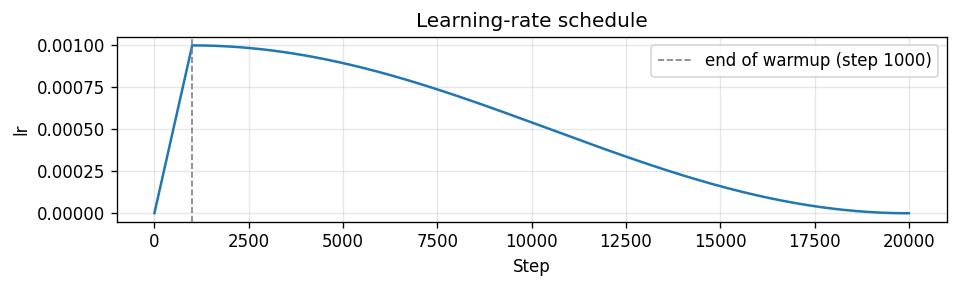

  hidden [0, 5, 6, 7, 10, 11]   visible [1, 2, 3, 4, 8, 9]
  hidden [2, 4, 6, 8, 10, 11]   visible [0, 1, 3, 5, 7, 9]
  hidden [0, 4, 8, 9, 10, 11]   visible [1, 2, 3, 5, 6, 7]
Our toy = 
 tensor([[[ 0,  0,  0],
         [ 1,  1,  1],
         [ 2,  2,  2],
         [ 3,  3,  3],
         [ 4,  4,  4]],

        [[10, 10, 10],
         [11, 11, 11],
         [12, 12, 12],
         [13, 13, 13],
         [14, 14, 14]]])
Result = 
 tensor([[[ 0,  0,  0],
         [ 2,  2,  2]],

        [[11, 11, 11],
         [14, 14, 14]]])


In [23]:
# Quick look at the three pretraining helpers.

# lr_at(): linear warmup to the peak over the first 5% of steps, then cosine decay to 0.
for step in [0, WARMUP_STEPS // 2, WARMUP_STEPS, N_PRETRAIN_STEPS // 2, N_PRETRAIN_STEPS - 1]:
    print(f"  lr at step {step:>5}: {lr_at(step, N_PRETRAIN_STEPS, PRETRAIN_LR, WARMUP_STEPS):.6f}")
steps = np.arange(N_PRETRAIN_STEPS)
plt.figure(figsize=(8, 2.5))
plt.plot(steps, [lr_at(s, N_PRETRAIN_STEPS, PRETRAIN_LR, WARMUP_STEPS) for s in steps])
plt.axvline(WARMUP_STEPS, color="gray", linestyle="--", linewidth=1, label=f"end of warmup (step {WARMUP_STEPS})")
plt.title("Learning-rate schedule"); plt.xlabel("Step"); plt.ylabel("lr"); plt.legend()
plt.tight_layout(); plt.show()

# sample_masks(): every row is one window. 6 hidden + 6 visible = all 12 patches; 10 and 11 always hidden.
hidden, visible = sample_masks(3)
for h, v in zip(hidden.tolist(), visible.tolist()):
    print(f"  hidden {h}   visible {v}")
    assert sorted(h + v) == list(range(PRETRAIN_WINDOW_PATCHES)) and {10, 11} <= set(h)

# gather_patches: picks, per window, the patches named by idx. Toy batch: 2 windows x 5 patches x 3 values,
#    where every value equals 10 * window + patch, so you can read off what was picked.
toy = torch.tensor([[[10 * b + n] * 3 for n in range(5)] for b in range(2)])
print("Our toy = \n", toy)
idx = torch.tensor([[0, 2], [1, 4]])   # window 0 -> patches 0 and 2, window 1 -> patches 1 and 4
print("Result = \n", gather_patches(toy, idx))

  [JEPA pretrain] step  1000/20000  loss 0.38331  val 0.4919
  [JEPA pretrain] step  2000/20000  loss 0.29279  val 0.4845
  [JEPA pretrain] step  3000/20000  loss 0.29848  val 0.4687
  [JEPA pretrain] step  4000/20000  loss 0.30718  val 0.4732
  [JEPA pretrain] step  5000/20000  loss 0.31250  val 0.4752
  [JEPA pretrain] step  6000/20000  loss 0.31489  val 0.4739
  [JEPA pretrain] step  7000/20000  loss 0.31554  val 0.4660
  [JEPA pretrain] step  8000/20000  loss 0.31229  val 0.4476
  [JEPA pretrain] step  9000/20000  loss 0.30752  val 0.4395
  [JEPA pretrain] step 10000/20000  loss 0.30162  val 0.4412
  [JEPA pretrain] step 11000/20000  loss 0.29709  val 0.4249
  [JEPA pretrain] step 12000/20000  loss 0.29046  val 0.4251
  [JEPA pretrain] step 13000/20000  loss 0.28520  val 0.4156
  [JEPA pretrain] step 14000/20000  loss 0.27958  val 0.4089
  [JEPA pretrain] step 15000/20000  loss 0.27514  val 0.4035
  [JEPA pretrain] step 16000/20000  loss 0.27112  val 0.3976
  [JEPA pretrain] step 1

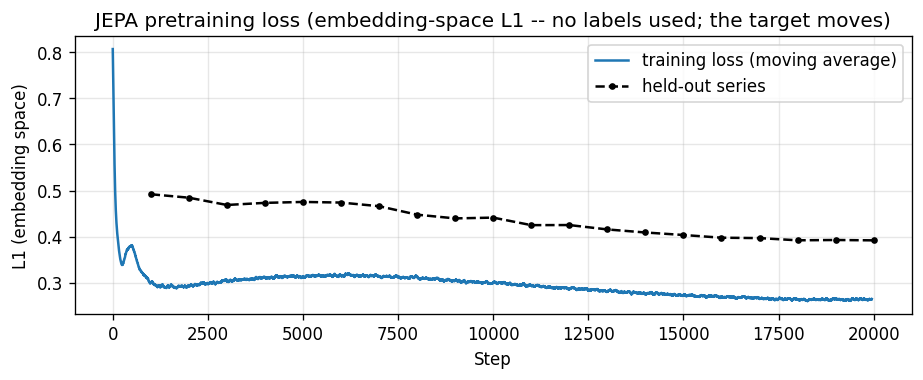

In [24]:
# One training step.
pretrain_counter = itertools.count()     # yields 0, 1, 2, ... ; re-running this cell restarts it

def pretrain_step():
    i = next(pretrain_counter)
    for g in opt_pretrain.param_groups:
        g["lr"] = lr_at(i, N_PRETRAIN_STEPS, PRETRAIN_LR, WARMUP_STEPS)
    # tau changes over time from 0.996 -> 1.0 across training
    tau = EMA_TAU_START + (1.0 - EMA_TAU_START) * i / N_PRETRAIN_STEPS
    raw = train_pool.sample_window(BATCH, PRETRAIN_WINDOW_PATCHES)             # (128, 192) raw values, (12 * 16 = 192)
    x_n, _, _ = normalize(raw)                                                 # (128, 192) z-scored
    patches = torch.tensor(to_patches(x_n), dtype=torch.float32).to(DEVICE)    # (128, 12, 16)
    mask_idx, ctx_idx = sample_masks(len(patches))                             # (128, 6) each
    # The target encoder sees the WHOLE window, then we select the hidden patches from its output.
    with torch.no_grad():       # no gradient tracking. The Grader is never trained by the loss.
        all_embed = target_encoder(patches, all_window_pos_ids)                # (128, 12, 128)
        all_embed = F.layer_norm(all_embed, (all_embed.size(-1),))             # (128, 12, 128)
        target_embed = gather_patches(all_embed, mask_idx)                     # (128, 6, 128)
    # The Encoder sees only the 6 visible patches, with their real positions.
    context_embed = model.encoder(gather_patches(patches, ctx_idx), ctx_idx)   # (128, 6, 128)
    # The predictor gets those 6 embeddings plus the positions of the 6 hidden patches, and guesses their embeddings.
    pred_embed = model.predictor(context_embed, ctx_idx, mask_idx)             # (128, 6, 128)
    # L1, as in V-JEPA / TS-JEPA
    loss = (pred_embed - target_embed).abs().mean()
    opt_pretrain.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(pretrain_params, 1.0)
    opt_pretrain.step()
    # The target_encoder follows all the time the model.encoder, but ~250 steps behind the model.encoder.
    # Each step closes 1 - 0.996 (EMA_TAU_START) = 0.004, i.e. 0.4% of the gap, so the lag is ~ 1 / 0.004 = 250 steps.
    # After 250 steps ~63% (0.996 ^ 250 = 0.37, hence 1 - 0.37 = 0.63) of any change is absorbed.
    ema_update(target_encoder, model.encoder, tau=tau)
    return loss.item()


def pretrain_val_loss():
    """Held-out embedding loss at the downstream setting: the last 2 patches from the first 8, on held-out series."""
    model.eval()
    target_encoder.eval()
    ctx_n, fut_n, _, _ = normalize(val_ctx, val_fut)
    full = np.concatenate([ctx_n, fut_n], axis=1)                      # (N, 160) = 10 patches
    patches = torch.tensor(to_patches(full), dtype=torch.float32).to(DEVICE)
    # Validation asks the forecasting question with no random masking.
    win_ids = torch.arange(N_CTX_PATCHES + N_TGT_PATCHES).to(DEVICE)    # positions 0..9
    with torch.no_grad():
        # Again, the target encoder sees the whole window.
        all_embed = target_encoder(patches, win_ids)
        all_embed = F.layer_norm(all_embed, (all_embed.size(-1),))
        tgt = all_embed[:, N_CTX_PATCHES:, :]                           # patches 8, 9 (the future)
        # Again, the encoder sees the context patches and guesses the future embeddings.
        pred = model.embed_target(patches[:, :N_CTX_PATCHES, :])        # guess from the first 8 only
        loss = (pred - tgt).abs().mean().item()
    model.train()
    return loss


t0 = time.time()
pretrain_loop = TrainingLoop(pretrain_step, val_fn=pretrain_val_loss, desc="JEPA pretrain")
pretrain_losses = pretrain_loop.run(N_PRETRAIN_STEPS, log_every=1000)
print(f"JEPA pretraining took {(time.time() - t0) / 60:.1f} min")

plt.figure(figsize=(9, 3))
plt.plot(np.convolve(pretrain_losses, np.ones(50) / 50, mode="valid"), label="training loss (moving average)")
plt.plot(*zip(*pretrain_loop.val_history), "k--", marker="o", markersize=3, label="held-out series")
plt.title("JEPA pretraining loss (embedding-space L1 -- no labels used; the target moves)")
plt.xlabel("Step"); plt.ylabel("L1 (embedding space)"); plt.legend()
plt.show()

In [25]:
# Compare the spread of trained Encoder with untrained Encoder with the same architecture and the same windows.

# (256, 128) raw
probe_ctx, _ = train_pool.sample(256)
# 256 random 128-step contexts, from different series and datasets, normalized and cut into patches.
probe_patches = torch.tensor(to_patches(normalize(probe_ctx)[0]), dtype=torch.float32).to(DEVICE)
print("probe_patches.shape = ", probe_patches.shape)

def embedding_spread(encoder):
    """Average per-dimension std across 256 different windows' summary embeddings."""
    was_training = encoder.training
    encoder.eval()
    with torch.no_grad():
        # The Encoder gives 8 embeddings per window, one per patch.
        # .mean(dim=1) averages them into one 128-number vector per window.
        # (256, 8, 128) -> (256, 128)
        emb = encoder(probe_patches, context_pos_ids).mean(dim=1)
    if was_training:
        encoder.train()
    # We measure how spread out those 256 vectors are.
    return emb.std(dim=0).mean().item()


spread_pretrained = embedding_spread(model.encoder)
spread_control = embedding_spread(Encoder().to(DEVICE))

# The pretrained Encoder’s embeddings are about 3x more spread out than the random one’s.
print(f"Pretrained Encoder    : {spread_pretrained:.4f}")
print(f"Untrained control     : {spread_control:.4f}")

probe_patches.shape =  torch.Size([256, 8, 16])
Pretrained Encoder    : 0.6442
Untrained control     : 0.1990


  [Fine-tune (full pipeline)] step   500/3000  loss 1.26635  val 0.9384
  [Fine-tune (full pipeline)] step  1000/3000  loss 1.04894  val 0.8868
  [Fine-tune (full pipeline)] step  1500/3000  loss 1.07303  val 0.9582
  [Fine-tune (full pipeline)] step  2000/3000  loss 1.04227  val 0.9076
  [Fine-tune (full pipeline)] step  2500/3000  loss 1.01486  val 1.0811
  [Fine-tune (full pipeline)] step  3000/3000  loss 1.01989  val 0.8933
  [Fine-tune (full pipeline)] restored best checkpoint: step 1000, val 0.8868


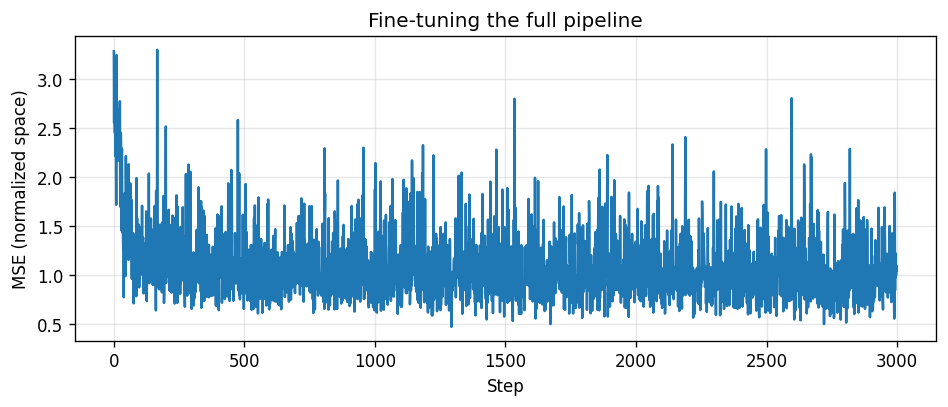

In [26]:
N_FINETUNE_STEPS = 3000   # supervised fine-tuning of the whole pipeline


def supervised_step_fn(m, opt, pool):
    """One gradient step of (context -> next 32) regression on the whole model."""
    def step():
        m.train()
        ctx_raw, fut_raw = pool.sample(BATCH)
        ctx_n, fut_n, _, _ = normalize(ctx_raw, fut_raw)
        patches = torch.tensor(to_patches(ctx_n), dtype=torch.float32).to(DEVICE)
        fut_t = torch.tensor(np.clip(fut_n, -10, 10), dtype=torch.float32).to(DEVICE)   # no single freak window gets to dominate the loss
        forecast_n = m(patches)
        loss = F.mse_loss(forecast_n, fut_t)
        opt.zero_grad()
        loss.backward()
        opt.step()
        return loss.item()
    return step


# Fine-tune the full pipeline (pretrained Encoder + Imagination, fresh Translator) on real forecasts.
finetune_loop = TrainingLoop(supervised_step_fn(model, optim.Adam(model.parameters(), lr=3e-4), train_pool),
                             val_fn=lambda: val_scaled_mae(model.forecast(val_ctx)), model=model,
                             desc="Fine-tune (full pipeline)")
finetune_loop.run(N_FINETUNE_STEPS, log_every=500)
jepa_pred = model.forecast(test_ctx)
jepa_table = test_table(jepa_pred)

plt.figure(figsize=(8, 3.5))
plt.plot(finetune_loop.losses)
plt.title("Fine-tuning the full pipeline"); plt.xlabel("Step"); plt.ylabel("MSE (normalized space)")
plt.tight_layout(); plt.show()

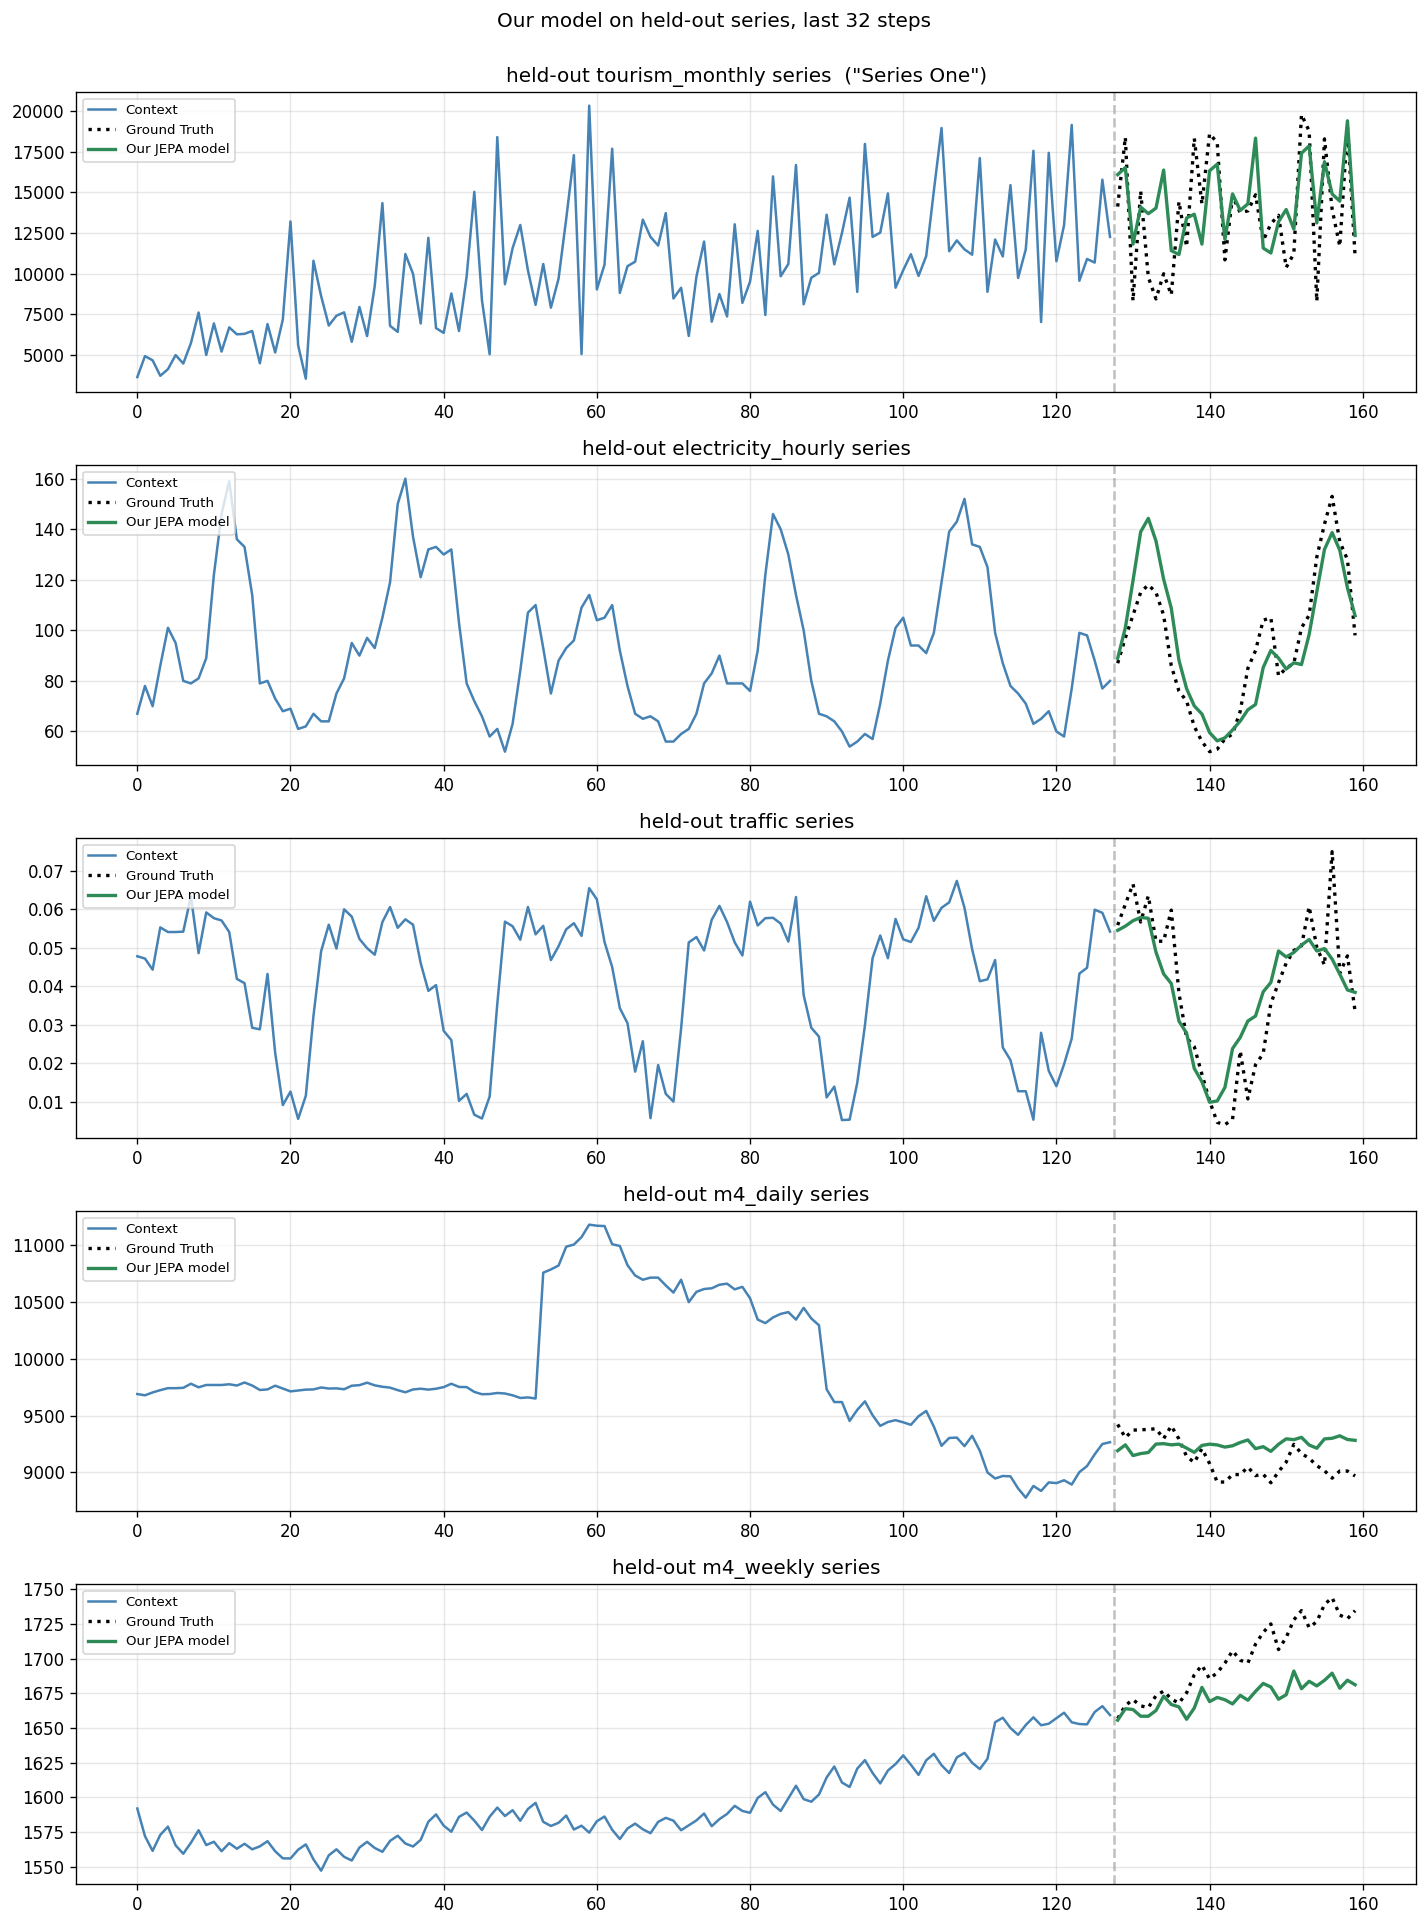

In [27]:
# Let's explore what our finished model predicts.

def plot_forecast(ax, context, future, point, quantiles, label, color, title):
    """Plot a single forecast with context, ground truth, and prediction."""
    x_ctx = np.arange(len(context))                             # History steps 0 to 127.
    x_fut = np.arange(len(context), len(context) + len(future)) # Future steps 128 to 159.
    ax.plot(x_ctx, context, label="Context", color="steelblue")
    ax.plot(x_fut, future, label="Ground Truth", color="black", linestyle=":", linewidth=2)
    ax.plot(x_fut, point[:len(future)], label=label, color=color, linewidth=2)
    # TimesFM provides quantiles, but our model doesn’t.
    if quantiles is not None:
        ax.fill_between(x_fut, quantiles[:len(future), 0], quantiles[:len(future), 8], color=color, alpha=0.2, label="80% CI")
    ax.axvline(len(context) - 0.5, color="gray", linestyle="--", alpha=0.5)
    ax.set_title(title); ax.legend(loc="upper left", fontsize=8)


showcase = [SERIES_ONE] + [next(i for i, n in enumerate(heldout_names) if n == ds and i != SERIES_ONE)
                           for ds in datasets_to_load if ds != "tourism_monthly"]
fig, axes = plt.subplots(len(showcase), 1, figsize=(12, 3.2 * len(showcase)))
for ax, idx in zip(axes, showcase):
    plot_forecast(ax, test_ctx[idx], test_fut[idx], jepa_pred[idx], None, "Our JEPA model", "seagreen",
                  f"held-out {heldout_names[idx]} series" + ("  (\"Series One\")" if idx == SERIES_ONE else ""))\

plt.suptitle("Our model on held-out series, last 32 steps", fontsize=12, y=1.0)
plt.tight_layout(); plt.show()

/opt/homebrew/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TimesFM forecast 364 held-out windows in 3s


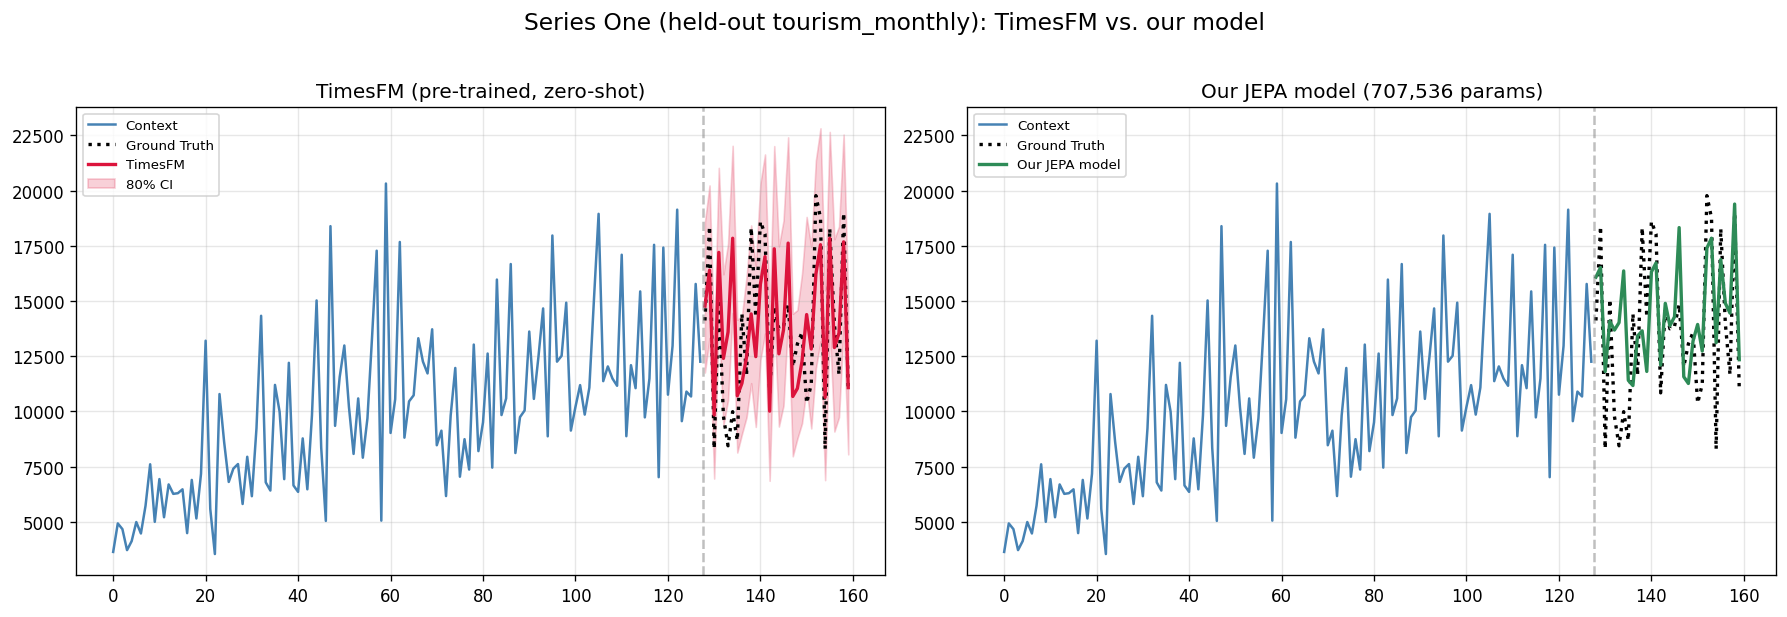

Series One        TimesFM     Our JEPA               Diff
MAE              2095.54     2209.27     +113.73 (+5.4%)
RMSE             2605.77     2726.00     +120.23 (+4.6%)
MAPE               17.17%       19.02%       +1.85 (+10.8%)


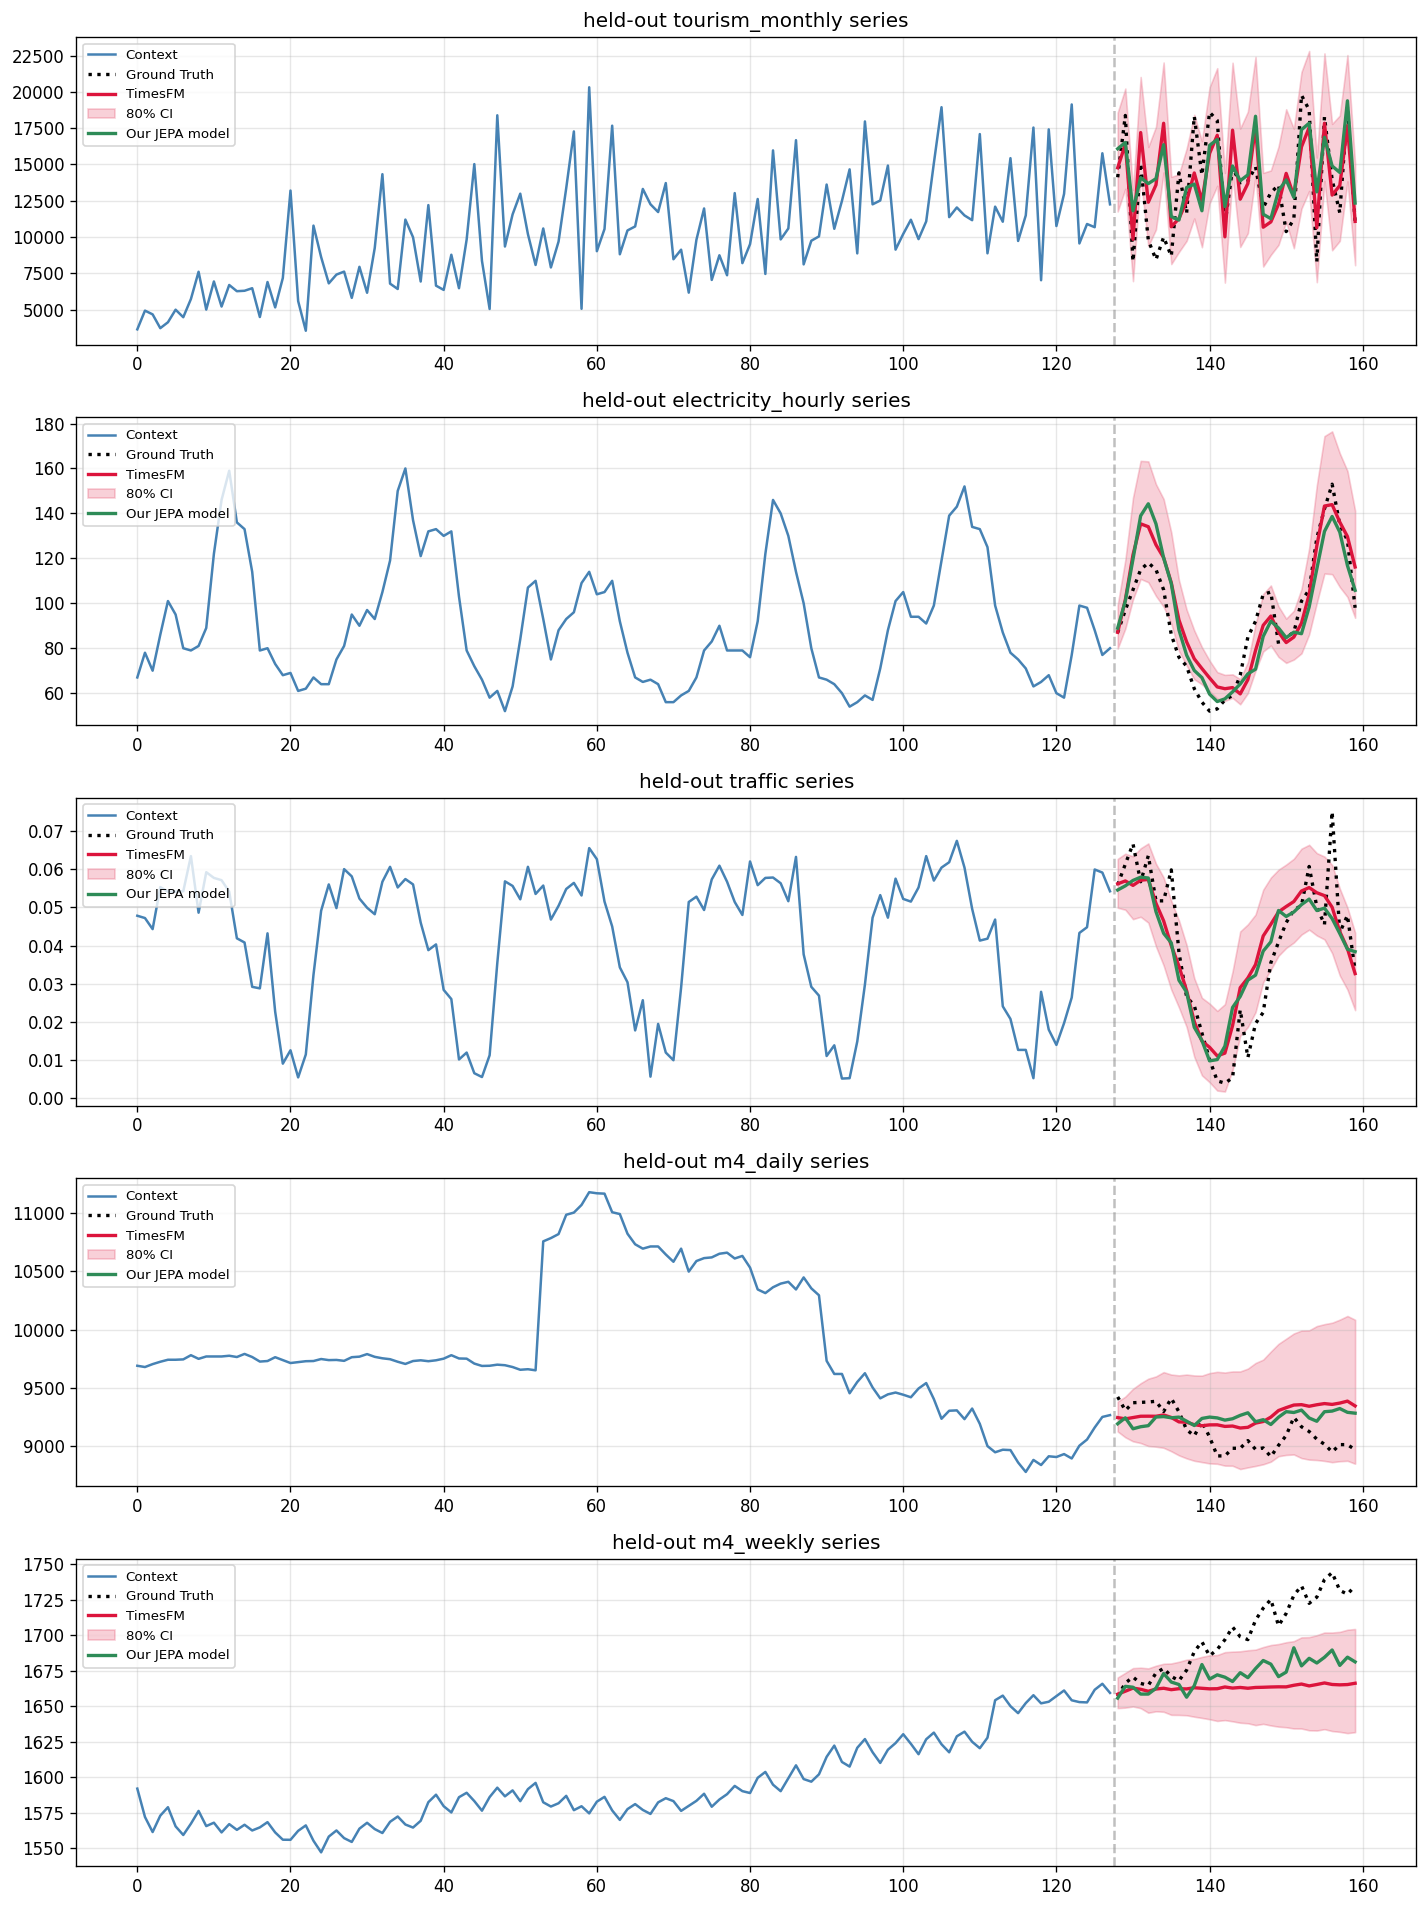


Scaled MAE on all 364 held-out test windows (MAE / naive MAE; 1.00 = repeat last value; lower is better)
             dataset    TimesFM   Our JEPA
  electricity_hourly      0.456      0.481
             traffic      0.540      0.414
            m4_daily      1.066      1.042
           m4_weekly      0.987      1.309
     tourism_monthly      0.446      0.768
                 all      0.835      0.845

Seam -- median |first forecast - last observed| / context sigma (lower is smoother; the data's own seam is the target)
        ground truth       0.13
             TimesFM       0.04
            Our JEPA       0.12

Each dataset counted equally: TimesFM 0.699, Our JEPA 0.803


In [28]:
# Let's put our model prediction next to TimesFM.

import timesfm


def timesfm_forecast(contexts, horizon=HORIZON):
    """(N, CONTEXT_LEN) -> (point (N, horizon), quantiles (N, horizon, 9): the 10th to 90th percentiles)."""
    tfm = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
    tfm.compile(forecast_config=timesfm.ForecastConfig(max_context=CONTEXT_LEN, max_horizon=horizon,
                                                       normalize_inputs=True, per_core_batch_size=32))
    point, quant = tfm.forecast(inputs=list(contexts), horizon=horizon)
    return point[:, :horizon], quant[:, :horizon, 1:]   # column 0 of the quantiles is the mean


t0 = time.time()

# The main forecast and the uncertainty values.
tfm_point, tfm_quant = timesfm_forecast(test_ctx)
print(f"TimesFM forecast {len(test_ctx)} held-out windows in {time.time() - t0:.0f}s")
tfm_table = test_table(tfm_point)

# 1. Series One side by side with the TimesFM.
idx = SERIES_ONE
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
plot_forecast(ax1, test_ctx[idx], test_fut[idx], tfm_point[idx], tfm_quant[idx], "TimesFM", "crimson", "TimesFM (pre-trained, zero-shot)")
plot_forecast(ax2, test_ctx[idx], test_fut[idx], jepa_pred[idx], None, "Our JEPA model", "seagreen",
              f"Our JEPA model ({model.count_parameters()['total']:,} params)")

y_min = min(ax1.get_ylim()[0], ax2.get_ylim()[0]); y_max = max(ax1.get_ylim()[1], ax2.get_ylim()[1])
ax1.set_ylim(y_min, y_max); ax2.set_ylim(y_min, y_max)
plt.suptitle("Series One (held-out tourism_monthly): TimesFM vs. our model", fontsize=14, y=1.02)
plt.tight_layout(); plt.show()

tfm_m, our_m = compute_metrics(tfm_point[idx], test_fut[idx]), compute_metrics(jepa_pred[idx], test_fut[idx])
print(f"{'Series One':<12} {'TimesFM':>12} {'Our JEPA':>12} {'Diff':>18}")
for k in ["MAE", "RMSE", "MAPE"]:
    d = our_m[k] - tfm_m[k]; unit = "%" if k == "MAPE" else ""
    print(f"{k:<12} {tfm_m[k]:>11.2f}{unit} {our_m[k]:>11.2f}{unit} {d:>+11.2f} ({100 * d / max(tfm_m[k], 1e-8):+.1f}%)")

# 2. One held-out series per dataset, both models on the same axes.
fig, axes = plt.subplots(len(showcase), 1, figsize=(12, 3.2 * len(showcase)))
for ax, i in zip(axes, showcase):
    plot_forecast(ax, test_ctx[i], test_fut[i], tfm_point[i], tfm_quant[i], "TimesFM", "crimson", f"held-out {heldout_names[i]} series")
    ax.plot(np.arange(CONTEXT_LEN, CONTEXT_LEN + HORIZON), jepa_pred[i], color="seagreen", linewidth=2, label="Our JEPA model")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

# 3. The whole held-out set: scaled MAE per dataset.
print(f"\nScaled MAE on all {len(test_ctx)} held-out test windows (MAE / naive MAE; 1.00 = repeat last value; lower is better)")
print(f"{'dataset':>20} {'TimesFM':>10} {'Our JEPA':>10}")
for k in list(datasets_to_load) + ["all"]:
    print(f"{k:>20} {tfm_table[k]:>10.3f} {jepa_table[k]:>10.3f}")
print(f"\nSeam -- median |first forecast - last observed| / context sigma (lower is smoother; the data's own seam is the target)")
print(f"{'ground truth':>20} {seam(test_fut, test_ctx):>10.2f}\n{'TimesFM':>20} {seam(tfm_point, test_ctx):>10.2f}\n{'Our JEPA':>20} {seam(jepa_pred, test_ctx):>10.2f}")

# 4. The same scores with every dataset counted once, instead of every window.
print(f"\nEach dataset counted equally: TimesFM {np.mean([tfm_table[k] for k in datasets_to_load]):.3f}, "
      f"Our JEPA {np.mean([jepa_table[k] for k in datasets_to_load]):.3f}")